In [1]:
'''Fine-tune model parameters using automated hyperparameter optimization tools like Optuna, 
incorporating pruning and early stopping to accelerate the search process in large datasets'''

'Fine-tune model parameters using automated hyperparameter optimization tools like Optuna, \nincorporating pruning and early stopping to accelerate the search process in large datasets'

In [2]:
# import core libraries for data handling and plotting
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# import optuna and scikit learn tools
import optuna
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error, root_mean_squared_error, mean_absolute_error, r2_score

In [4]:
# load admission dataset from csv
df = pd.read_csv('Adm.csv')

In [5]:
# inspect dataset structure and sample records
print('dataset dimensions:', df.shape)
print('first 3 records:')
print(df.head(3))

dataset dimensions: (1000, 12)
first 3 records:
   Serial No.  GRE Score  ...                             University_Name  region
0           1        337  ...    Indian Institute of Technology Kharagpur    East
1           2        324  ...  National Institute of Technology Karnataka   South
2           3        316  ...                          Gujarat University    West

[3 rows x 12 columns]


In [6]:
# verify data cleanliness and missing value counts
print('missing values check:')
print(df.isnull().sum())

missing values check:
Serial No.              0
GRE Score               0
TOEFL Score             0
University Rating       0
SOP                     0
LOR                     0
CGPA                    0
Research                0
Chance of Admit         0
Application_DateTime    0
University_Name         0
region                  0
dtype: int64


In [7]:
# extract feature matrix and target column
features = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
target = 'Chance of Admit'

X = df[features]
y = df[target]

print('features selected:', features)
print('target column:', target)

features selected: ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
target column: Chance of Admit


In [8]:
# split data into train validation and test subsets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=42)

print('train subset size:', len(X_tr))
print('validation subset size:', len(X_val))
print('test subset size:', len(X_test))

train subset size: 600
validation subset size: 200
test subset size: 200


In [9]:
# standardize features using standard scaler
scaler = StandardScaler()
X_tr_scaled = scaler.fit_transform(X_tr)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)
X_train_scaled = scaler.fit_transform(X_train)

print('features successfully standardized')

features successfully standardized


In [10]:
# train and evaluate un-tuned baseline model
baseline_model = SGDRegressor(random_state=42)
baseline_model.fit(X_train_scaled, y_train)

baseline_pred = baseline_model.predict(X_test_scaled)
baseline_r2 = r2_score(y_test, baseline_pred)
baseline_mse = mean_squared_error(y_test, baseline_pred)
baseline_rmse = root_mean_squared_error(y_test, baseline_pred)
baseline_mae = mean_absolute_error(y_test, baseline_pred)

print('baseline test r2:', round(baseline_r2, 4))
print('baseline test mse:', round(baseline_mse, 6))
print('baseline test rmse:', round(baseline_rmse, 4))
print('baseline test mae:', round(baseline_mae, 4))

baseline test r2: 0.9398
baseline test mse: 0.000616
baseline test rmse: 0.0248
baseline test mae: 0.0196


In [11]:
# define optuna objective function with pruning and early stopping
def objective(trial):
    alpha = trial.suggest_float('alpha', 1e-4, 1e-1, log=True)
    eta0 = trial.suggest_float('eta0', 1e-3, 1e-1, log=True)
    penalty = trial.suggest_categorical('penalty', ['l2', 'l1', 'elasticnet'])
    l1_ratio = trial.suggest_float('l1_ratio', 0.1, 0.9) if penalty == 'elasticnet' else 0.15
    
    model = SGDRegressor(
        alpha=alpha,
        eta0=eta0,
        penalty=penalty,
        l1_ratio=l1_ratio,
        learning_rate='optimal',
        random_state=42
    )
    
    max_epochs = 50
    patience = 5
    best_loss = float('inf')
    patience_counter = 0
    
    for epoch in range(max_epochs):
        model.partial_fit(X_tr_scaled, y_tr)
        val_pred = model.predict(X_val_scaled)
        val_loss = mean_squared_error(y_val, val_pred)
        
        # optuna pruning
        trial.report(val_loss, epoch)
        if trial.should_prune():
            raise optuna.TrialPruned()
            
        # early stopping mechanism
        if val_loss < best_loss:
            best_loss = val_loss
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                break
                
    return best_loss

In [12]:
# create optuna study configured with median pruner
pruner = optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=5)
study = optuna.create_study(direction='minimize', pruner=pruner)

print('optuna study created with median pruner for search acceleration')

optuna study created with median pruner for search acceleration


In [13]:
# execute automated hyperparameter optimization search
start_time = time.time()
study.optimize(objective, n_trials=35)
tuning_time = time.time() - start_time

print('hyperparameter search finished in:', round(tuning_time, 2), 'seconds')

hyperparameter search finished in: 0.85 seconds


In [14]:
# inspect optimization summary and pruning statistics
completed_trials = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
pruned_trials = [t for t in study.trials if t.state == optuna.trial.TrialState.PRUNED]

print('total trials evaluated:', len(study.trials))
print('completed trials count:', len(completed_trials))
print('pruned trials count:', len(pruned_trials))
pruning_ratio = (len(pruned_trials) / len(study.trials)) * 100
print('search acceleration: pruned', round(pruning_ratio, 2), '% of unpromising trials')

total trials evaluated: 35
completed trials count: 12
pruned trials count: 23
search acceleration: pruned 65.71 % of unpromising trials


In [15]:
# retrieve optimal hyperparameter values
print('best hyperparameters identified:')
for param, val in study.best_params.items():
    print(f'  {param}: {val}')
print('best validation loss (mse):', round(study.best_value, 6))

best hyperparameters identified:
  alpha: 0.017421201053376432
  eta0: 0.007232019600715985
  penalty: l2
best validation loss (mse): 0.0006


In [16]:
# train final model using best parameters on full training set
best_params = study.best_params.copy()
penalty = best_params.pop('penalty')
alpha = best_params.pop('alpha')
eta0 = best_params.pop('eta0')
l1_ratio = best_params.pop('l1_ratio', 0.15)

final_model = SGDRegressor(
    alpha=alpha,
    eta0=eta0,
    penalty=penalty,
    l1_ratio=l1_ratio,
    learning_rate='optimal',
    random_state=42
)
final_model.fit(X_train_scaled, y_train)

print('final model trained with optimal parameters')

final model trained with optimal parameters


In [17]:
# evaluate final tuned model on unseen test set
opt_pred = final_model.predict(X_test_scaled)

opt_r2 = r2_score(y_test, opt_pred)
opt_mse = mean_squared_error(y_test, opt_pred)
opt_rmse = root_mean_squared_error(y_test, opt_pred)
opt_mae = mean_absolute_error(y_test, opt_pred)

comparison_summary = pd.DataFrame({
    'metric': ['r2 score', 'mean squared error', 'root mean squared error', 'mean absolute error'],
    'baseline_model': [baseline_r2, baseline_mse, baseline_rmse, baseline_mae],
    'optuna_tuned_model': [opt_r2, opt_mse, opt_rmse, opt_mae]
})

print('baseline vs optuna tuned performance:')
print(comparison_summary.to_string(index=False))

baseline vs optuna tuned performance:
                 metric  baseline_model  optuna_tuned_model
               r2 score        0.939839            0.937419
     mean squared error        0.000616            0.000641
root mean squared error        0.024818            0.025312
    mean absolute error        0.019597            0.019577


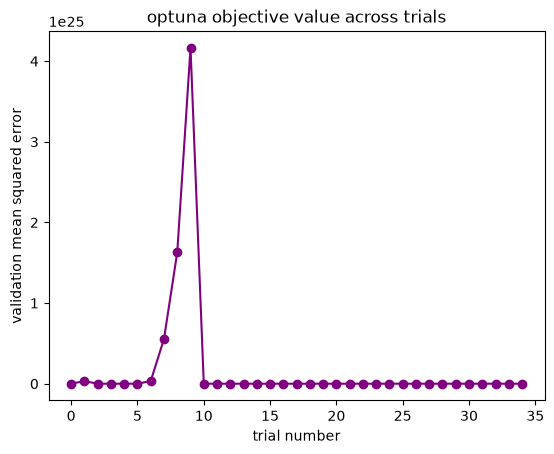

In [18]:
# plot optuna optimization loss history across trials
trial_numbers = [t.number for t in study.trials if t.value is not None]
trial_values = [t.value for t in study.trials if t.value is not None]

plt.plot(trial_numbers, trial_values, marker='o', color='purple')
plt.title('optuna objective value across trials')
plt.xlabel('trial number')
plt.ylabel('validation mean squared error')
plt.show()

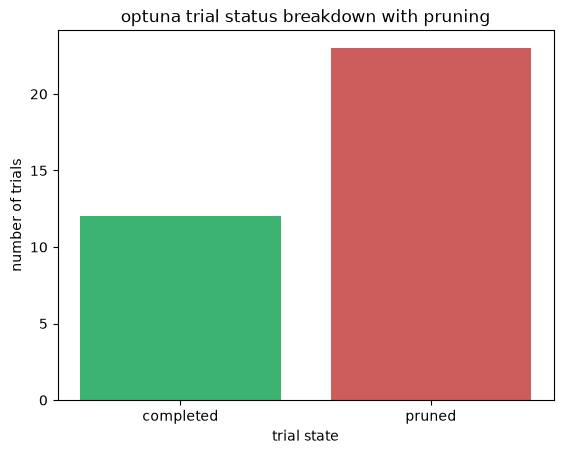

In [19]:
# plot trial completion status breakdown showing search acceleration
status_counts = pd.Series({
    'completed': len(completed_trials),
    'pruned': len(pruned_trials)
})

plt.bar(status_counts.index, status_counts.values, color=['mediumseagreen', 'indianred'])
plt.title('optuna trial status breakdown with pruning')
plt.xlabel('trial state')
plt.ylabel('number of trials')
plt.show()